# Swimmer Plot

**Family:** Healthcare & life sciences &nbsp;|&nbsp; **Library:** matplotlib / seaborn &nbsp;|&nbsp; **Level:** Intermediate

> *Healthcare & life sciences:* Clinical trials, survival, oncology, hospital quality and operations, epidemiology and patient-level records.

> ⚠️ Examples use simulated data. De-identify patient data before analysing it in notebooks: executed notebooks store their outputs.

## Design purpose

One horizontal bar per patient shows time on treatment, with markers for key events (response onset, progression, ongoing therapy). It tells each patient's story, which summary curves hide.

## When to use

- Show individual treatment duration and response in early-phase oncology trials
- Show durability of response alongside time to response
- Show any per-entity timeline with events (customer lifecycles, equipment maintenance)

## Avoid when

- There are more than about 50 patients (bars become unreadable; use Kaplan–Meier curves)
- Only aggregate statistics matter

## Alternatives

- Kaplan–Meier curve
- Gantt chart
- Event-chart / lasagna plot

## Design tips

- Sort bars by duration, and color by best overall response
- Use distinct marker shapes for events and an arrow for 'still on treatment'

## Example

Synthetic phase I cohort of 24 patients: months on treatment, best response, and event markers.

### Setup

In [1]:
%matplotlib inline
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Library style: categorical colors in fixed order, recessive axes, hairline grid.
PALETTE = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100",
           "#e87ba4", "#008300", "#6250d6", "#e34948"]
SEQ_CMAP = "Blues"      # sequential: one hue, light -> dark
DIV_CMAP = "RdBu_r"     # diverging: two opposite hues, neutral midpoint
GRAY = "#b8b7b1"        # de-emphasised marks
plt.rcParams.update({
    "figure.figsize": (8, 4.8), "figure.dpi": 110, "figure.facecolor": "#fcfcfb",
    "axes.facecolor": "#fcfcfb", "axes.edgecolor": "#c9c8c3", "axes.linewidth": 0.8,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#e6e5e1", "grid.linewidth": 0.6, "axes.axisbelow": True,
    "axes.prop_cycle": plt.cycler(color=PALETTE),
    "axes.titlesize": 13, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.labelcolor": "#52514e", "xtick.color": "#52514e", "ytick.color": "#52514e",
    "text.color": "#0b0b0b", "font.size": 10, "lines.linewidth": 2,
    "legend.frameon": False,
})

### Data

In [2]:
rng = np.random.default_rng(13)
n = 24
resp = rng.choice(["Complete response", "Partial response", "Stable disease", "Progressive disease"],
                  n, p=[0.12, 0.33, 0.33, 0.22])
base = {"Complete response": 22, "Partial response": 15, "Stable disease": 8, "Progressive disease": 3}
dur = np.array([max(1.0, rng.normal(base[r], base[r] * 0.35)) for r in resp]).round(1)
responder = np.isin(resp, ["Complete response", "Partial response"])
onset = np.where(responder, np.minimum(dur * 0.9, rng.uniform(1.5, 4, n)), np.nan).round(1)
ongoing = (rng.random(n) < 0.3) & (resp != "Progressive disease")   # best response PD means it progressed
progressed = ~ongoing & (resp != "Complete response")
df = pd.DataFrame({"patient": [f"P{i:02d}" for i in range(1, n + 1)], "months": dur,
                   "best_response": resp, "response_onset": onset,
                   "progressed": progressed, "ongoing": ongoing}).sort_values("months")
df.head()

,patient,months,best_response,response_onset,progressed,ongoing
18,P19,1.5,Progressive disease,NaN,True,False
11,P12,2.2,Progressive disease,NaN,True,False
9,P10,3.2,Progressive disease,NaN,True,False
22,P23,3.2,Progressive disease,NaN,True,False
2,P03,3.3,Progressive disease,NaN,True,False


### Plot

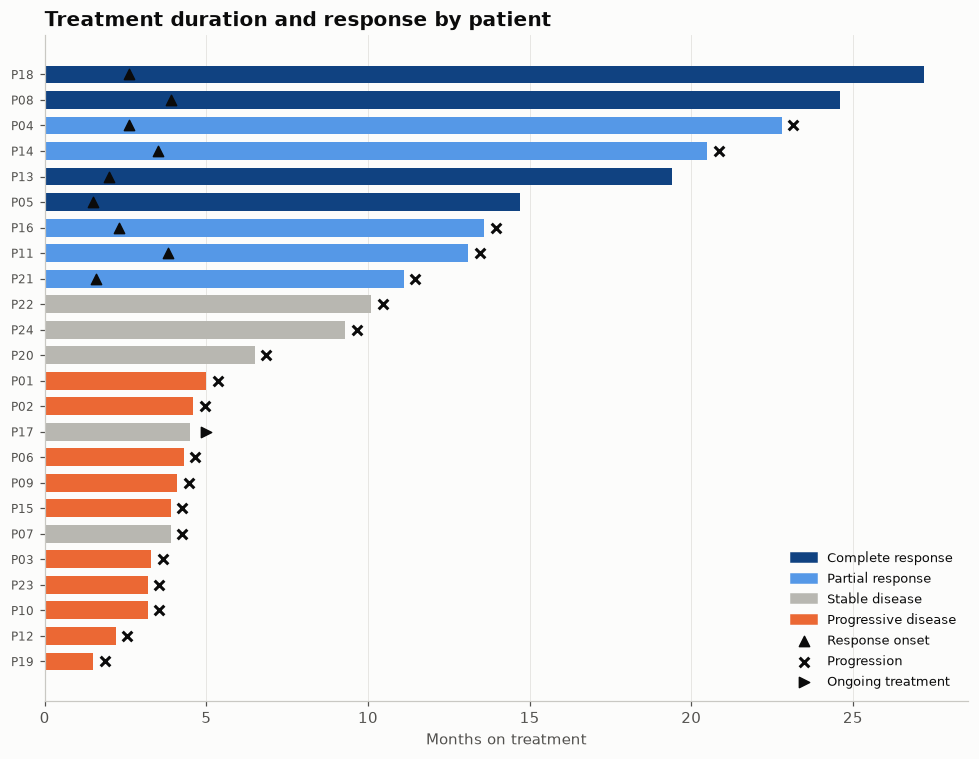

In [3]:
colors = {"Complete response": "#104281", "Partial response": "#5598e7",
          "Stable disease": GRAY, "Progressive disease": PALETTE[1]}
fig, ax = plt.subplots(figsize=(9, 7))
y = np.arange(len(df))
ax.barh(y, df.months, color=df.best_response.map(colors), height=0.7)
ax.scatter(df.response_onset, y, marker="^", s=45, color="#0b0b0b", zorder=3, label="Response onset")
pr = df.progressed.values
ax.scatter(df.months[pr] + 0.35, y[pr], marker="x", s=40, color="#0b0b0b", zorder=3, label="Progression")
og = df.ongoing.values
ax.scatter(df.months[og] + 0.5, y[og], marker=">", s=45, color="#0b0b0b", zorder=3,
           label="Ongoing treatment")
ax.set_yticks(y, df.patient, fontsize=8)
ax.grid(axis="y", visible=False)
ax.set_xlabel("Months on treatment")
ax.set_title("Treatment duration and response by patient")
from matplotlib.patches import Patch
handles = [Patch(color=c, label=k) for k, c in colors.items()]
h2, _ = ax.get_legend_handles_labels()
ax.legend(handles=handles + h2, loc="lower right", fontsize=8.5)
fig.tight_layout()
plt.show()

## How to read it

Each bar is one patient's time on treatment, colored by best response. Triangles mark when a response began, crosses mark progression, and arrows mean the patient is still on treatment. Bars that end with no marker (here, complete responders) stopped treatment without progressing.

---
Standalone script: [`swimmer_plot.py`](swimmer_plot.py) &nbsp;·&nbsp; [Catalogue](../../README.md) &nbsp;·&nbsp; [Gallery](../../gallery/index.html)